In [1]:
#importing pandas and numpy for preprocessing of the data
import pandas as pd
import numpy as np

In [2]:
#extracting data
df=pd.read_csv("Titanic-Dataset.csv")
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
#checking for unique values
print(df["Embarked"].unique())  #have 3 unique value
df["Cabin"].unique() #many unique value but some have same value
df["Ticket"].unique() #have primary key features 
df["Parch"].unique()  
df["SibSp"].unique()  
  


['S' 'C' 'Q' nan]


array([1, 0, 3, 4, 2, 5, 8])

In [4]:
#checking for is null
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [5]:
#processing null values
df=df.dropna(subset=["Embarked"])
df["Age"]=df["Age"].fillna(df["Age"].mean()).copy()

In [6]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [7]:
#encode the values of the label and aslo using one shot-encoding 
from sklearn.preprocessing import LabelEncoder

lb=LabelEncoder()
# df["Embarked"]=lb.fit_transform(df["Embarked"])
df["Sex"]=lb.fit_transform(df["Sex"])
df["Cabin"]=lb.fit_transform(df["Cabin"]) #the null values is also encoded 

#onehsot encoding 
df=pd.get_dummies(df,columns=["Embarked"],drop_first=True)
df.head() 

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,146,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,80,False,False
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,146,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,54,False,True
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,146,False,True


In [8]:
#assigning the values
X=df.drop(columns=["Name","PassengerId","Ticket","Survived","Cabin"])
Y=df["Survived"]

In [9]:
#applying PCA for dimension reduction
# from sklearn.decomposition import PCA

# pca=PCA(n_components=2)

# X_pca=pca.fit_transform(X)

In [10]:
#train and test splitting of the data
from sklearn.model_selection import train_test_split

X_train,X_test,Y_train,Y_test =train_test_split(X,Y,test_size=0.2,random_state=42)

In [11]:
#scaling of the data 
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

# ANN classifier

In [12]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

import torch
import torch.nn as nn
from torch.utils.data import DataLoader,TensorDataset

In [13]:
#changing ir data into tensor form for neural network
X_train_tensor=torch.tensor(X_train_scaled,dtype=torch.float32)
X_test_tensor=torch.tensor(X_test_scaled,dtype=torch.float32)

Y_train_tensor=torch.tensor(Y_train.values,dtype=torch.long)
Y_test_tensor=torch.tensor(Y_test.values,dtype=torch.long)

In [14]:
#train and test dataset of tensor for dataloader
train_dataset=TensorDataset(X_train_tensor,Y_train_tensor)
test_dataset=TensorDataset(X_test_tensor,Y_test_tensor)

In [15]:
#dataloader for definig the batch size and structure of data that is feed to the NN
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=32,shuffle=True)

In [16]:
#defining the model

class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()

        self.model=nn.Sequential(
            nn.Linear(X_train.shape[1],32),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(32,16),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(16,2)
        )

    def forward(self,x):
        return self.model(x)

In [17]:
#selecting the model
model=ANN()

#selecting OPTIMIZER for wight update and loss function
import torch.optim as optim
criteria=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=0.001,weight_decay=1e-3)

In [18]:
#training the model
epochs=150
train_total_loss=[]
val_total_loss=[]

for epoch in range(epochs):
    model.train()
    train_loss=0.0

    for xb,yb in train_loader:
        model.zero_grad()
        
        outputs=model(xb)
        loss=criteria(outputs,yb)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    epochs_train_loss = train_loss/len(train_loader)
    train_total_loss.append(epochs_train_loss)

    model.eval()
    val_loss=0.0

    with torch.no_grad():
        for xb,yb in test_loader:
            outputs=model(xb)
            loss2=criteria(outputs,yb)

            val_loss += loss2.item()
            
    epochs_val_loss= val_loss/len(test_loader)
    val_total_loss.append(epochs_val_loss)
    
    print(f"for epoch ({epoch+1}/{epochs}) ===> trainig loss = {epochs_train_loss} and val loss = {epochs_val_loss}")

for epoch (1/150) ===> trainig loss = 0.6833985318308291 and val loss = 0.628266453742981
for epoch (2/150) ===> trainig loss = 0.6155775448550349 and val loss = 0.5754193663597107
for epoch (3/150) ===> trainig loss = 0.579192367584809 and val loss = 0.5187097638845444
for epoch (4/150) ===> trainig loss = 0.5260344847388889 and val loss = 0.4725443472464879
for epoch (5/150) ===> trainig loss = 0.4974410831928253 and val loss = 0.4568126052618027
for epoch (6/150) ===> trainig loss = 0.4870407374008842 and val loss = 0.42934632301330566
for epoch (7/150) ===> trainig loss = 0.4747964428818744 and val loss = 0.45137453079223633
for epoch (8/150) ===> trainig loss = 0.4675039856330208 and val loss = 0.4224577893813451
for epoch (9/150) ===> trainig loss = 0.4585692714089933 and val loss = 0.44893498222033185
for epoch (10/150) ===> trainig loss = 0.4367052549901216 and val loss = 0.4446389675140381
for epoch (11/150) ===> trainig loss = 0.4550187056479247 and val loss = 0.4332375725110

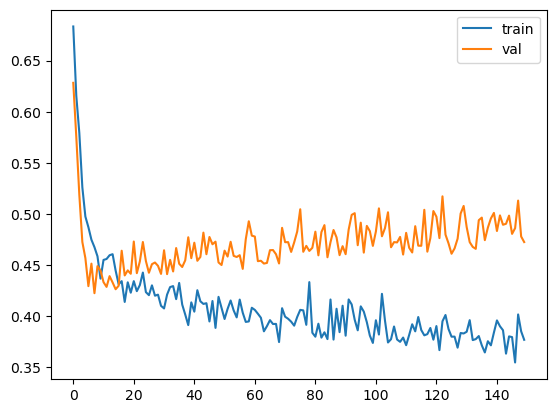

In [19]:
train_data=pd.DataFrame({
    "train data":train_total_loss,
    "val data":val_total_loss
})

import matplotlib.pyplot as plt
plt.plot(train_data["train data"],label="train")
plt.plot(train_data["val data"],label="val")
plt.legend() 

plt.savefig("images/learning_curve.jpg")
#the dataset is tooo small for neural network thus,it started to memorize the data

In [20]:
model.eval()

y_pred=[]
y_true=[] 

with torch.no_grad():

    outputs=model(X_test_tensor)

    _,predicted=torch.max(outputs,1)

    y_pred=predicted.cpu().numpy()
    y_true=Y_test_tensor.cpu().numpy()

In [21]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

print(f"accuracy = {accuracy_score(y_true,y_pred)}")

cr=classification_report(y_true,y_pred,target_names=["Not Survived","Survived"])
print(cr)

accuracy = 0.8258426966292135
              precision    recall  f1-score   support

Not Survived       0.84      0.89      0.86       109
    Survived       0.81      0.72      0.76        69

    accuracy                           0.83       178
   macro avg       0.82      0.81      0.81       178
weighted avg       0.82      0.83      0.82       178



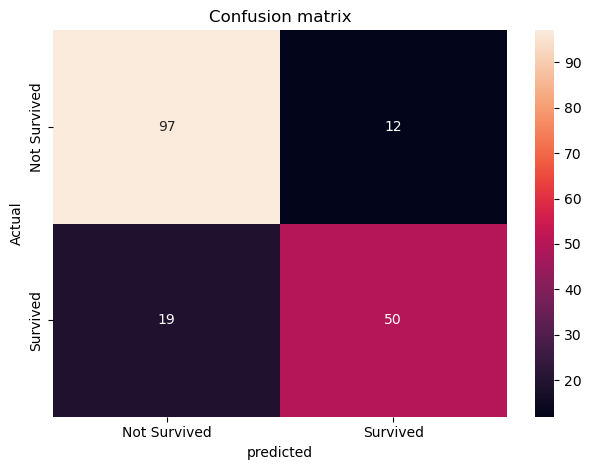

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

cm=confusion_matrix(y_true,y_pred)

sns.heatmap(cm,annot=True,
           xticklabels=["Not Survived","Survived"],
           yticklabels=["Not Survived","Survived"])
plt.xlabel("predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
plt.tight_layout()
plt.savefig("images/Confusion_matrix.jpg")